# Task 1B – Lọc ảnh, khử nhiễu, gradient, cạnh và lọc miền tần số

**FCVG101 – FruitSort Vision Assistant · Task 1: Core Image Analysis Engine**

Ảnh đầu vào lấy từ **dataset trái cây của Task 2** (Kaggle: táo, chuối, cam). Đây chính là loại ảnh người dùng sẽ upload vào app ở Task 3, nên các hàm trong `src/filtering.py` được viết để app gọi lại được.

Nội dung:

1. **Tích chập 2-D tự cài** (NumPy) và kiểm chứng với OpenCV.
2. **Khử nhiễu**: Box, Gaussian, Median, Bilateral trên 2 loại nhiễu. Đo bằng MSE, PSNR, SSIM so với ảnh sạch.
3. **Gradient và cạnh**: Sobel, Canny tự chọn ngưỡng. Đo F1 của bản đồ cạnh khi ảnh có nhiễu. Tách đường viền quả.
4. **Miền tần số**: phổ FFT; lọc low-pass/high-pass (ideal, Gaussian, Butterworth) và hiện tượng ringing; kiểm chứng định lý tích chập; **khử nhiễu tuần hoàn bằng notch filter**.

Ảnh chính: kaggle_train_orange_16.jpg | kích thước (450, 448) | OpenCV 5.0.0


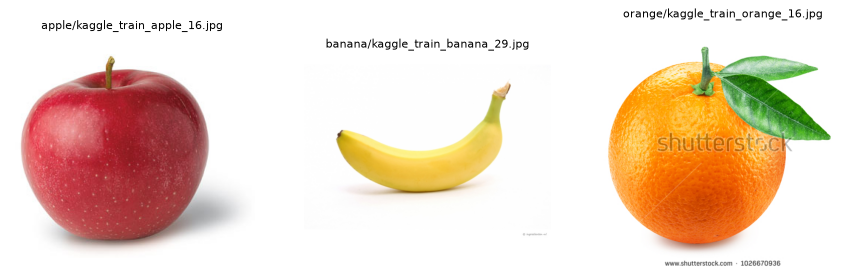

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import filtering as flt

FRUIT = ROOT.parent / 'datasets' / 'fruits' / 'raw'
MAIN_IMG = FRUIT / 'orange' / 'kaggle_train_orange_16.jpg'
GALLERY = [FRUIT / 'apple' / 'kaggle_train_apple_16.jpg',
           FRUIT / 'banana' / 'kaggle_train_banana_29.jpg',
           FRUIT / 'orange' / 'kaggle_train_orange_16.jpg']
OUT = ROOT / 'results' / '1B'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42

plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 110})
pd.set_option('display.float_format', lambda v: f'{v:.4g}')

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight')
    plt.show()

def show(ax, img, title='', cmap='gray'):
    if img.ndim == 3:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(img, cmap=cmap)
    ax.set_title(title, fontsize=9); ax.axis('off')

img = flt.load_image(MAIN_IMG, max_side=512)
gray = flt.to_gray(img)
print('Ảnh chính:', MAIN_IMG.name, '| kích thước', gray.shape[::-1], '| OpenCV', cv2.__version__)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, p in zip(ax, GALLERY):
    show(a, flt.load_image(p), f'{p.parent.name}/{p.name}')
save(fig, 'input_gallery.png')

## 1. Tích chập 2-D tự cài

- **Tương quan (correlation):** $g(x,y)=\sum_{i,j} k(i,j)\,f(x+i,\,y+j)$.
- **Tích chập (convolution):** giống tương quan nhưng **lật kernel** theo cả hai trục. Với kernel đối xứng (Box, Gaussian) thì hai phép này cho kết quả như nhau. Với kernel lệch (Sobel) thì đổi dấu.
- `cv2.filter2D` thực chất tính **tương quan**.
- Cài đặt dùng `sliding_window_view` và `einsum` (`src/filtering.py::correlate2d`), biên ảnh xử lý theo kiểu reflect-101 giống OpenCV.

Thời gian Gaussian 5x5: tự cài 6.7 ms | OpenCV 2.30 ms (OpenCV tối ưu SIMD/đa luồng)


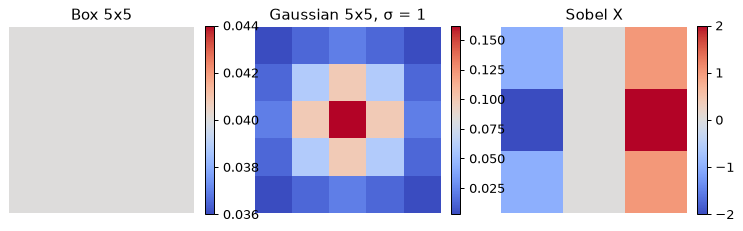

,max_abs_diff
correlate2d vs cv2.filter2D (Gaussian 5x5),1.421e-13
correlate2d(Box 5x5) vs cv2.blur,5.684e-14
convolve2d(Sobel X) vs filter2D(kernel đã lật),0
"convolve2d(Sobel X) + correlate2d(Sobel X) (phải = 0, vì đổi dấu)",0
gaussian_kernel vs cv2.getGaussianKernel,2.776e-17
median_filter tự cài vs cv2.medianBlur (5x5),0


In [2]:
g = gray.astype(float)
kg = flt.gaussian_kernel(5, 1.0)
checks = {
    'correlate2d vs cv2.filter2D (Gaussian 5x5)': np.abs(flt.correlate2d(g, kg) - cv2.filter2D(g, -1, kg)).max(),
    'correlate2d(Box 5x5) vs cv2.blur': np.abs(flt.correlate2d(g, flt.box_kernel(5)) - cv2.blur(g, (5, 5))).max(),
    'convolve2d(Sobel X) vs filter2D(kernel đã lật)': np.abs(flt.convolve2d(g, flt.SOBEL_X) - cv2.filter2D(g, -1, flt.SOBEL_X[::-1, ::-1])).max(),
    'convolve2d(Sobel X) + correlate2d(Sobel X) (phải = 0, vì đổi dấu)': np.abs(flt.convolve2d(g, flt.SOBEL_X) + flt.correlate2d(g, flt.SOBEL_X)).max(),
    'gaussian_kernel vs cv2.getGaussianKernel': np.abs(kg - np.outer(cv2.getGaussianKernel(5, 1.0), cv2.getGaussianKernel(5, 1.0))).max(),
    'median_filter tự cài vs cv2.medianBlur (5x5)': float(np.abs(flt.median_filter(gray, 5).astype(int) - cv2.medianBlur(gray, 5).astype(int)).max()),
}
t0 = time.perf_counter(); flt.correlate2d(g, kg); t_mine = time.perf_counter() - t0
t0 = time.perf_counter(); cv2.filter2D(g, -1, kg); t_cv = time.perf_counter() - t0
verify = pd.DataFrame({'max_abs_diff': checks})
verify.to_csv(OUT / 'convolution_verification.csv')
print(f'Thời gian Gaussian 5x5: tự cài {t_mine * 1000:.1f} ms | OpenCV {t_cv * 1000:.2f} ms (OpenCV tối ưu SIMD/đa luồng)')

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
for a, (k, t) in zip(ax, [(flt.box_kernel(5), 'Box 5x5'), (kg, 'Gaussian 5x5, σ = 1'), (flt.SOBEL_X, 'Sobel X')]):
    im = a.imshow(k, cmap='coolwarm'); a.set_title(t); a.axis('off'); plt.colorbar(im, ax=a, fraction=0.046)
save(fig, 'kernels.png')
verify

## 2. Khử nhiễu

Tạo 2 loại nhiễu từ ảnh sạch, dùng seed cố định để chạy lại cho cùng kết quả:

- **Nhiễu Gaussian** σ = 20: nhiễu cộng, ví dụ nhiễu cảm biến khi thiếu sáng.
- **Nhiễu muối tiêu** 5 %: một số pixel bị đặt thành đen hoặc trắng hẳn, ví dụ lỗi truyền dữ liệu.

Mỗi bộ lọc chạy với kích thước kernel 3, 5 và 7. Vì có ảnh sạch làm tham chiếu nên đo được:

- **MSE**: càng thấp càng tốt.
- **PSNR** (dB): càng cao càng tốt.
- **SSIM** (0–1): càng cao càng tốt; phản ánh việc giữ cấu trúc và cạnh tốt hơn MSE.

In [3]:
clean = gray
noisy = {'Gaussian σ=20': flt.add_gaussian_noise(clean, 20, SEED),
         'Muối tiêu 5%': flt.add_salt_pepper(clean, 0.05, SEED)}
FILTERS, KS = ['box', 'gaussian', 'median', 'bilateral'], [3, 5, 7]
rows = []
for nname, n in noisy.items():
    rows.append(dict(noise=nname, filter='(không lọc)', k=0, **flt.quality(clean, n)))
    for f in FILTERS:
        for k in KS:
            rows.append(dict(noise=nname, filter=f, k=k, **flt.quality(clean, flt.apply_filter(n, f, k))))
den = pd.DataFrame(rows)
den.to_csv(OUT / 'denoising_metrics.csv', index=False)
best = den[den.k > 0].loc[lambda d: d.groupby('noise').PSNR_dB.idxmax()]
print('Bộ lọc tốt nhất theo PSNR cho từng loại nhiễu:')
print(best[['noise', 'filter', 'k', 'PSNR_dB', 'SSIM']].to_string(index=False))
den.pivot_table(index=['noise', 'filter'], columns='k', values='PSNR_dB')

Bộ lọc tốt nhất theo PSNR cho từng loại nhiễu:
        noise    filter  k  PSNR_dB   SSIM
Gaussian σ=20 bilateral  7    28.77 0.8231
 Muối tiêu 5%    median  3    30.52 0.9112


k                            0     3     5     7
noise         filter                            
Gaussian σ=20 (không lọc) 23.3   NaN   NaN   NaN
              bilateral    NaN 27.54 28.57 28.77
              box          NaN 27.09 26.06 25.47
              gaussian     NaN 27.63 27.29  26.8
              median       NaN 27.68 26.89 26.52
Muối tiêu 5%  (không lọc) 17.1   NaN   NaN   NaN
              bilateral    NaN 17.29 17.43 17.54
              box          NaN 24.63 25.38 25.29
              gaussian     NaN 24.18 25.59  25.9
              median       NaN 30.52 27.49 26.73

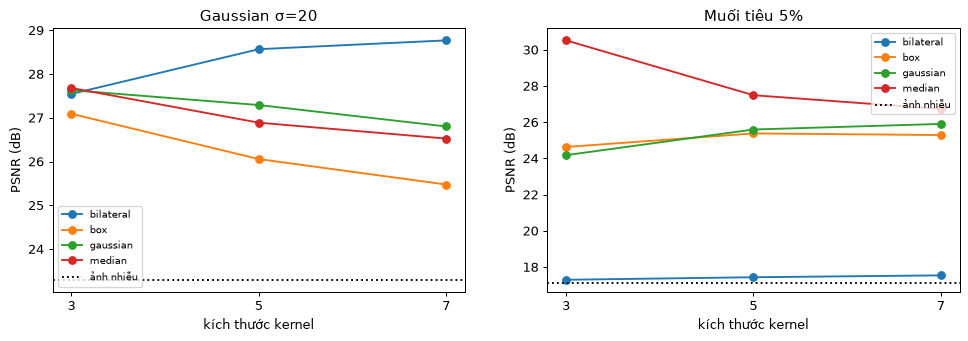

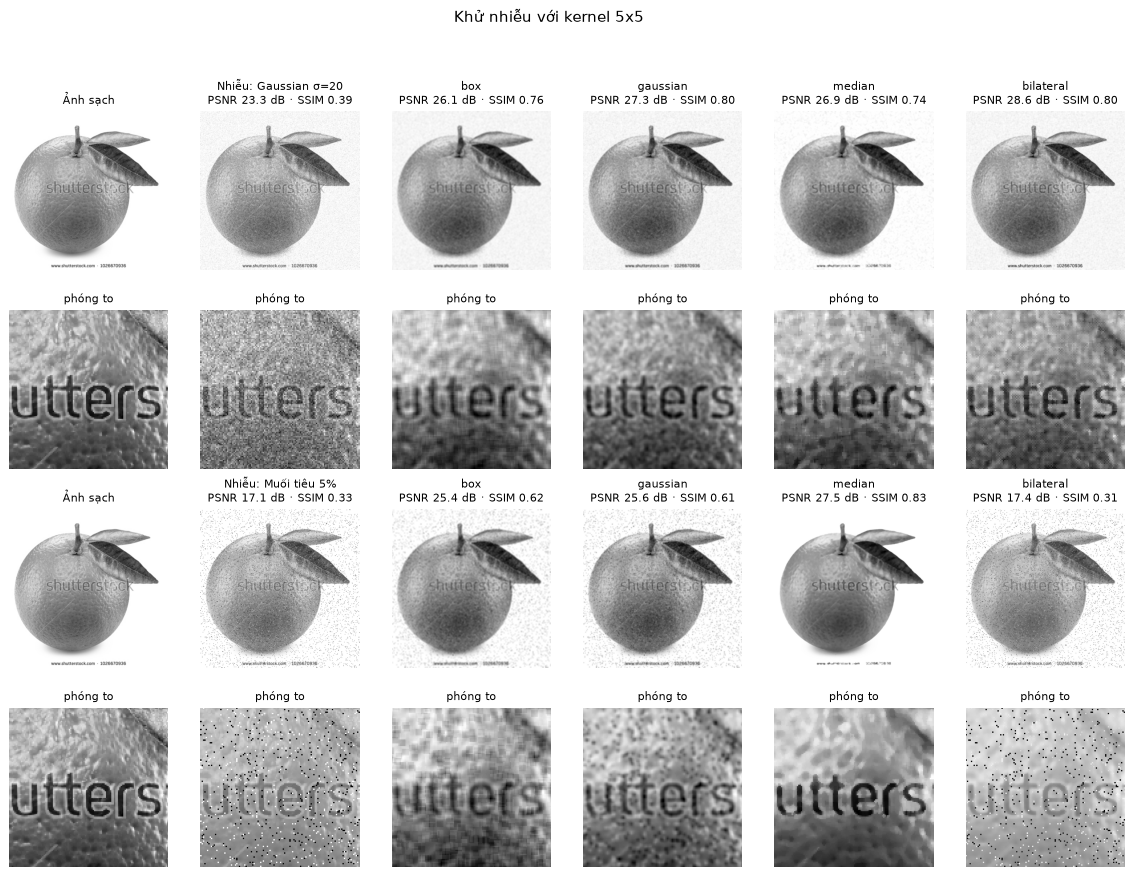

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for a, (nname, sub) in zip(ax, den[den.k > 0].groupby('noise')):
    for f, s in sub.groupby('filter'):
        a.plot(s.k, s.PSNR_dB, 'o-', label=f)
    a.axhline(den[(den.noise == nname) & (den.k == 0)].PSNR_dB.iloc[0], color='k', ls=':', label='ảnh nhiễu')
    a.set_title(nname); a.set_xlabel('kích thước kernel'); a.set_ylabel('PSNR (dB)'); a.set_xticks(KS); a.legend(fontsize=8)
save(fig, 'denoising_psnr_vs_k.png')

K_SHOW = 5
y0, x0, s = gray.shape[0] // 3, gray.shape[1] // 3, 120      # vùng phóng to để thấy cạnh bị mờ
fig, ax = plt.subplots(4, 6, figsize=(16, 11))
for r, (nname, n) in enumerate(noisy.items()):
    outs = [('Ảnh sạch', clean), (f'Nhiễu: {nname}', n)] + [(f, flt.apply_filter(n, f, K_SHOW)) for f in FILTERS]
    for c, (t, im) in enumerate(outs):
        q = flt.quality(clean, im)
        lbl = t if c == 0 else f'{t}\nPSNR {q["PSNR_dB"]:.1f} dB · SSIM {q["SSIM"]:.2f}'
        show(ax[2 * r, c], im, lbl)
        show(ax[2 * r + 1, c], im[y0:y0 + s, x0:x0 + s], 'phóng to')
fig.suptitle(f'Khử nhiễu với kernel {K_SHOW}x{K_SHOW}')
save(fig, 'denoising_grid.png')

**Nhận xét** (đối chiếu với bảng số ở trên):

- **Nhiễu Gaussian** có kỳ vọng bằng 0. Lấy trung bình có trọng số (Gaussian) hoặc làm mượt có giữ cạnh (Bilateral) triệt tiêu nó tốt. Box cũng giảm nhiễu nhưng làm nhoè cạnh nhiều hơn.
- **Nhiễu muối tiêu** là các giá trị ngoại lai. Bộ lọc tuyến tính chỉ "rải" chúng ra vùng xung quanh. **Median** loại bỏ ngoại lai vì trung vị không bị kéo lệch bởi vài pixel 0 hoặc 255.
- **Kernel lớn hơn** giảm nhiễu nhiều hơn nhưng làm mờ chi tiết. Đường PSNR theo k cho thấy điểm cân bằng tối ưu.

## 3. Gradient và cạnh

**Sobel** xấp xỉ đạo hàm theo hai trục: $G_x$, $G_y$. Độ lớn gradient là $\sqrt{G_x^2+G_y^2}$, hướng là $\operatorname{atan2}(G_y, G_x)$. Ảnh hướng gradient hiển thị bằng màu: hue = hướng, độ sáng = độ lớn.

**Canny** = làm mượt Gaussian → Sobel → **loại bỏ điểm không cực đại** (non-maximum suppression, giúp cạnh mảnh 1 px) → **ngưỡng kép với trễ** (hysteresis). Hai ngưỡng được **chọn tự động** theo trung vị độ sáng: $[(1-0.33)\,m,\ (1+0.33)\,m]$.

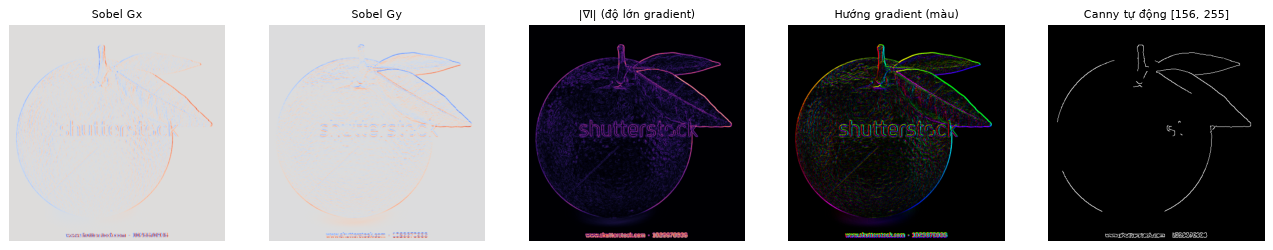

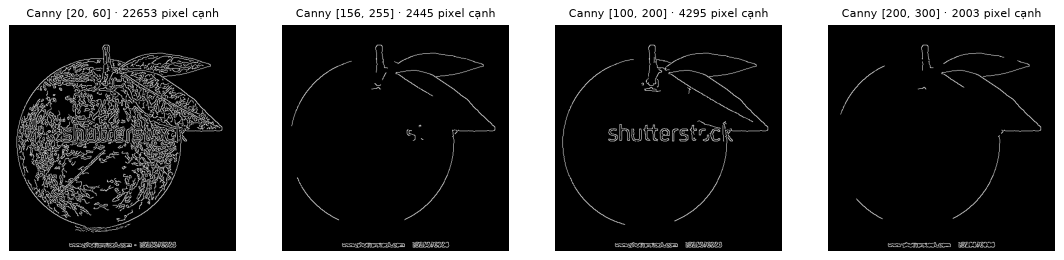

In [5]:
gx, gy, mag, ang = flt.sobel(gray)
hsv = np.zeros((*gray.shape, 3), np.uint8)
hsv[..., 0] = ((ang + np.pi) / (2 * np.pi) * 179).astype(np.uint8)
hsv[..., 1] = 255
hsv[..., 2] = flt.to_uint8(np.clip(mag, 0, np.percentile(mag, 99)))
orient = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
edges_auto, (lo, hi) = flt.canny_auto(gray)
fig, ax = plt.subplots(1, 5, figsize=(18, 3.8))
show(ax[0], gx, 'Sobel Gx', 'coolwarm'); show(ax[1], gy, 'Sobel Gy', 'coolwarm')
show(ax[2], mag, '|∇I| (độ lớn gradient)', 'magma'); show(ax[3], orient, 'Hướng gradient (màu)')
show(ax[4], edges_auto, f'Canny tự động [{lo}, {hi}]')
save(fig, 'sobel_canny.png')

fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (l, h) in zip(ax, [(20, 60), (lo, hi), (100, 200), (200, 300)]):
    e = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), l, h)
    show(a, e, f'Canny [{l}, {h}] · {int((e > 0).sum())} pixel cạnh')
save(fig, 'canny_thresholds.png')

**Nhiễu ảnh hưởng đến cạnh ra sao, và lọc trước giúp được bao nhiêu?**

Lấy cạnh Canny của **ảnh sạch** làm tham chiếu. Trên ảnh nhiễu Gaussian, chạy Canny với **cùng ngưỡng** sau từng cách lọc trước. Đo **Precision / Recall / F1**, cho phép lệch 2 px:

- **Precision thấp**: có nhiều cạnh giả do nhiễu.
- **Recall thấp**: mất cạnh thật vì ảnh bị làm mờ quá tay.

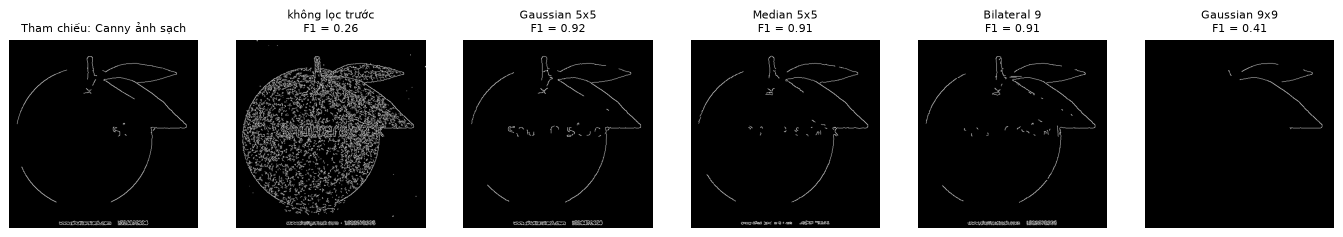

,precision,recall,F1,edge_pixels
prefilter,,,,
không lọc trước,0.1494,1,0.26,19587
Gaussian 5x5,0.8915,0.9464,0.9181,2589
Median 5x5,0.9104,0.9027,0.9065,2244
Bilateral 9,0.8967,0.9182,0.9073,2555
Gaussian 9x9,1,0.2589,0.4113,602


In [6]:
ref = cv2.Canny(cv2.GaussianBlur(clean, (5, 5), 0), lo, hi)
n = noisy['Gaussian σ=20']
pre = {'không lọc trước': n,
       'Gaussian 5x5': cv2.GaussianBlur(n, (5, 5), 0),
       'Median 5x5': cv2.medianBlur(n, 5),
       'Bilateral 9': cv2.bilateralFilter(n, 9, 50, 50),
       'Gaussian 9x9': cv2.GaussianBlur(n, (9, 9), 0)}
edge_rows, edge_maps = [], {}
for name, im in pre.items():
    e = cv2.Canny(im, lo, hi); edge_maps[name] = e
    edge_rows.append(dict(prefilter=name, **flt.edge_f1(ref, e)))
edge_df = pd.DataFrame(edge_rows).set_index('prefilter')
edge_df.to_csv(OUT / 'edge_f1.csv')

fig, ax = plt.subplots(1, 6, figsize=(19, 3.6))
show(ax[0], ref, 'Tham chiếu: Canny ảnh sạch')
for a, (name, e) in zip(ax[1:], edge_maps.items()):
    show(a, e, f'{name}\nF1 = {edge_df.loc[name, "F1"]:.2f}')
save(fig, 'edges_under_noise.png')
edge_df

**Ứng dụng cho FruitSort: tách vùng quả và đường viền.** Vỏ quả (đỏ, vàng, cam) có **độ bão hoà màu** (kênh S của HSV) cao, còn nền chụp sản phẩm thường trắng hoặc xám. Cách làm:

1. Làm mượt kênh S, rồi lấy **ngưỡng Otsu** (chọn ngưỡng tự động sao cho phương sai giữa hai lớp lớn nhất).
2. Dùng phép mở/đóng hình thái học (morphological opening/closing) để bỏ đốm nhiễu, rồi lấp các lỗ trong vùng quả.
3. Lấy **contour lớn nhất**, tính diện tích và khung bao. **Đường viền** chính là cạnh của mặt nạ (mask).

Ảnh thứ 4 có nền phức tạp (bát, khăn) được giữ lại **có chủ đích** để minh hoạ giới hạn: phương pháp cổ điển dựa vào một đặc trưng đơn giản sẽ thất bại khi nền cũng nhiều màu. Đó cũng là lý do Task 2 cần CNN.

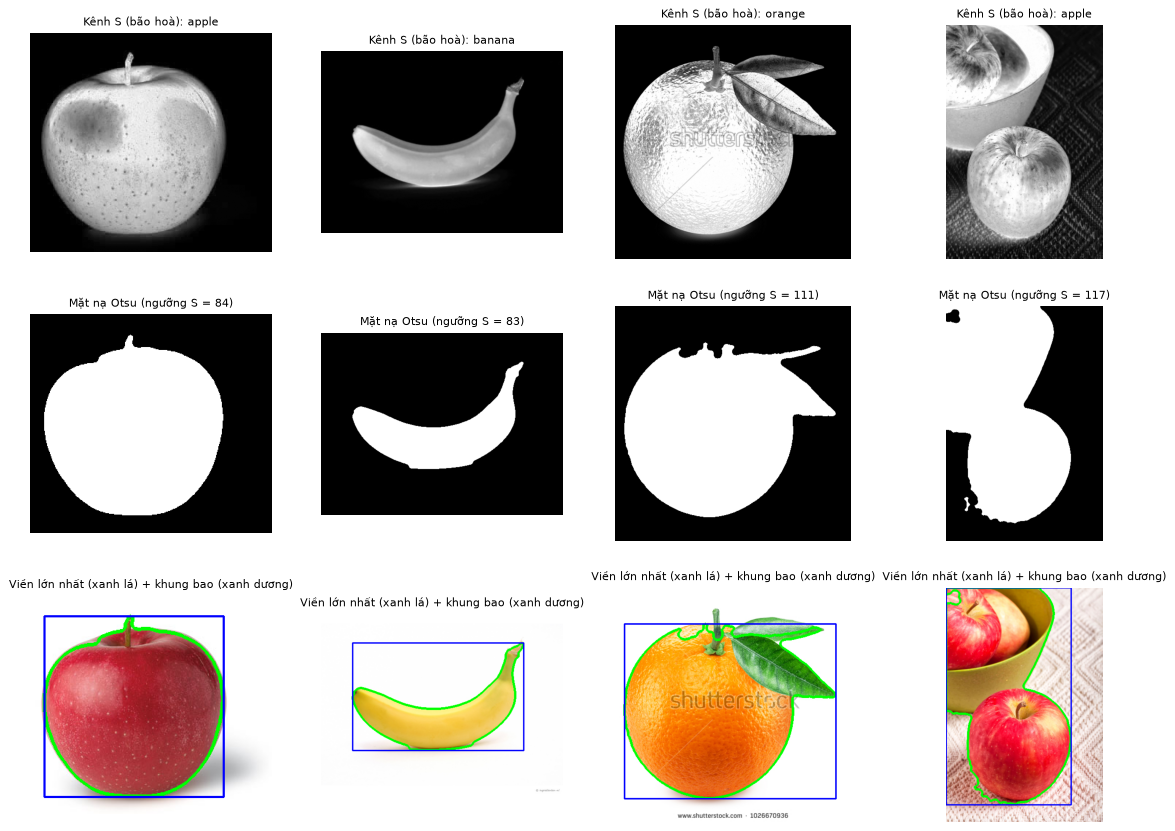

,image,otsu_threshold_S,area_px,area_ratio,bbox_wh
0,kaggle_train_apple_16.jpg,84,4.527e+04,0.4531,"(246, 248)"
1,kaggle_train_banana_29.jpg,83,3.06e+04,0.1556,"(361, 227)"
2,kaggle_train_orange_16.jpg,111,8.903e+04,0.4416,"(404, 334)"
3,kaggle_train_apple_24.jpg,117,9.502e+04,0.5426,"(273, 474)"


In [7]:
OUTLINE_SET = GALLERY + [FRUIT / 'apple' / 'kaggle_train_apple_24.jpg']   # ảnh cuối: nền phức tạp
fig, ax = plt.subplots(3, 4, figsize=(16, 11.5))
outline_rows = []
for c, p in enumerate(OUTLINE_SET):
    im = flt.load_image(p)
    cnt, mask, boundary = flt.fruit_outline(im)
    _, otsu_t = flt.fruit_mask(im)
    vis = im.copy()
    if cnt is not None:
        cv2.drawContours(vis, [cnt], -1, (0, 255, 0), 3)
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 2)
        outline_rows.append(dict(image=p.name, otsu_threshold_S=otsu_t, area_px=cv2.contourArea(cnt),
                                 area_ratio=cv2.contourArea(cnt) / (im.shape[0] * im.shape[1]), bbox_wh=(w, h)))
    show(ax[0, c], cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[..., 1], f'Kênh S (bão hoà): {p.parent.name}')
    show(ax[1, c], mask, f'Mặt nạ Otsu (ngưỡng S = {otsu_t:.0f})')
    show(ax[2, c], vis, 'Viền lớn nhất (xanh lá) + khung bao (xanh dương)')
save(fig, 'fruit_outline.png')
pd.DataFrame(outline_rows)

## 4. Miền tần số (Fourier)

$F(u,v)=\mathcal{F}\{f(x,y)\}$. Sau `fftshift`, tần số thấp nằm ở tâm phổ. Vùng tâm ứng với các mảng màu lớn và mượt; vùng ngoài ứng với cạnh, chi tiết và nhiễu.

Lọc trong miền tần số gồm 3 bước: nhân phổ với hàm truyền $H(u,v)$, biến đổi ngược `ifftshift` rồi `ifft2`, và lấy phần thực. So sánh ba dạng $H$ có **cùng bán kính cắt** $D_0 = 30$:

- **Ideal**: cắt đột ngột (hàm bậc thang).
- **Gaussian**: chuyển tiếp mượt.
- **Butterworth** bậc 2: nằm giữa hai loại trên.

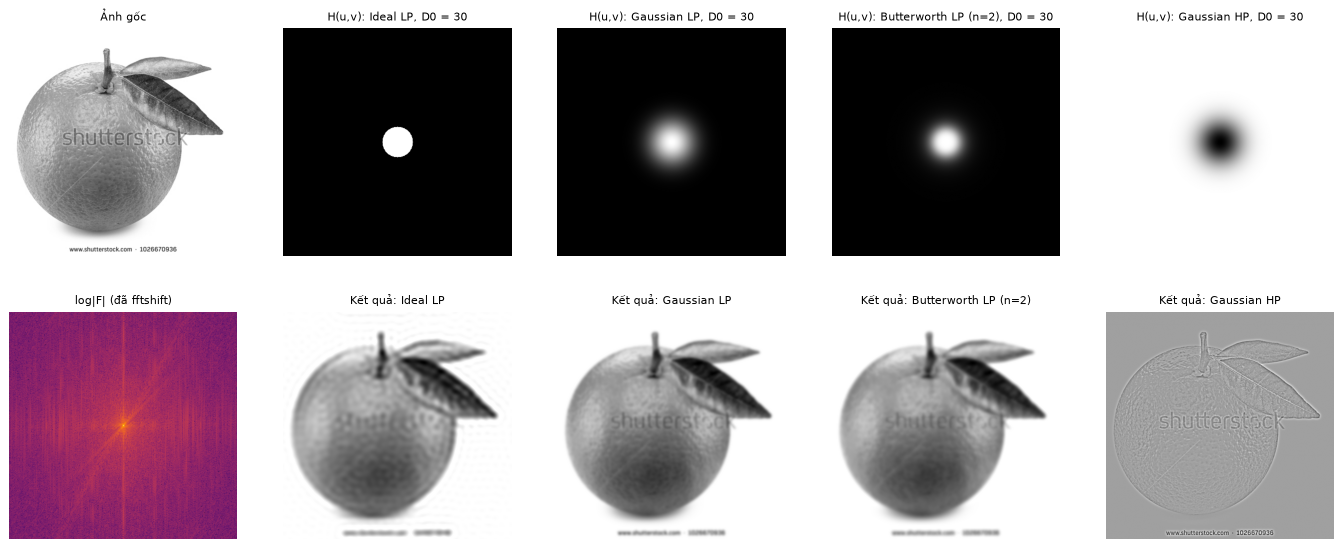

In [8]:
F = flt.fft_shifted(gray)
D0 = 30
masks = {'Ideal LP': flt.lowpass_mask(gray.shape, D0, 'ideal'),
         'Gaussian LP': flt.lowpass_mask(gray.shape, D0, 'gaussian'),
         'Butterworth LP (n=2)': flt.lowpass_mask(gray.shape, D0, 'butterworth'),
         'Gaussian HP': flt.highpass_mask(gray.shape, D0, 'gaussian')}
results = {k: flt.apply_frequency_filter(gray, H) for k, H in masks.items()}

fig, ax = plt.subplots(2, 5, figsize=(19, 7.5))
show(ax[0, 0], gray, 'Ảnh gốc'); show(ax[1, 0], flt.log_magnitude(F), 'log|F| (đã fftshift)', 'inferno')
for c, (k, H) in enumerate(masks.items(), start=1):
    show(ax[0, c], H, f'H(u,v): {k}, D0 = {D0}', 'gray')
    out = results[k]
    show(ax[1, c], flt.to_uint8(out) if 'HP' in k else np.clip(out, 0, 255), f'Kết quả: {k}')
save(fig, 'fft_filters.png')

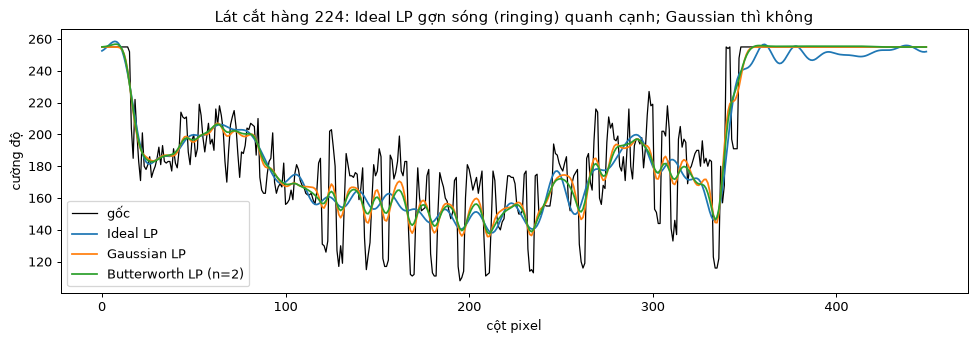

,PSNR vs gốc (dB),dao động so với Gaussian LP ở vùng phẳng (std)
Ideal LP,25.86,3.335
Butterworth LP (n=2),26.38,1.063
Gaussian LP,26.76,0


In [9]:
# Ringing: lát cắt 1 hàng pixel đi qua mép quả
row = gray.shape[0] // 2
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(gray[row], 'k', lw=1, label='gốc')
for k in ['Ideal LP', 'Gaussian LP', 'Butterworth LP (n=2)']:
    ax.plot(results[k][row], lw=1.4, label=k)
ax.set_xlabel('cột pixel'); ax.set_ylabel('cường độ'); ax.legend()
ax.set_title(f'Lát cắt hàng {row}: Ideal LP gợn sóng (ringing) quanh cạnh; Gaussian thì không')
save(fig, 'ringing_profile.png')

def ringing_score(out, ref):
    # năng lượng dao động: độ lệch so với bản Gaussian LP ở vùng phẳng (gradient ảnh gốc nhỏ)
    flat = flt.sobel(ref)[2] < np.percentile(flt.sobel(ref)[2], 50)
    return float(np.std((out - results['Gaussian LP'])[flat]))
ring = pd.DataFrame({k: {'PSNR vs gốc (dB)': flt.psnr(gray, np.clip(results[k], 0, 255)),
                         'dao động so với Gaussian LP ở vùng phẳng (std)': ringing_score(results[k], gray)}
                     for k in ['Ideal LP', 'Butterworth LP (n=2)', 'Gaussian LP']}).T
ring

**Kiểm chứng định lý tích chập:** tích chập trong miền không gian ⇔ nhân trong miền tần số.

Bộ lọc Gaussian không gian với độ lệch chuẩn $\sigma$ (pixel) có hàm truyền
$H(f_x,f_y)=\exp\!\big(-2\pi^2\sigma^2(f_x^2+f_y^2)\big)$, với $f$ tính theo chu kỳ/pixel.

Phép so sánh: tích chập không gian dùng `correlate2d` tự cài với biên **tuần hoàn**, giống giả thiết của DFT. Lọc tần số dùng `apply_frequency_filter`. Hai kết quả phải gần như trùng nhau; phần sai khác nhỏ còn lại là do kernel không gian bị cắt ở ±3σ.

In [10]:
sig = 3.0
k = flt.gaussian_kernel(int(6 * sig) | 1, sig); r = k.shape[0] // 2
spatial = flt.correlate2d(np.pad(gray.astype(float), r, mode='wrap'), k)[r:-r, r:-r]
fy = np.fft.fftshift(np.fft.fftfreq(gray.shape[0]))[:, None]
fx = np.fft.fftshift(np.fft.fftfreq(gray.shape[1]))[None, :]
H_gauss = np.exp(-2 * np.pi ** 2 * sig ** 2 * (fx ** 2 + fy ** 2))
freq = flt.apply_frequency_filter(gray, H_gauss)
d = np.abs(spatial - freq)
print(f'σ = {sig}: chênh lệch không gian vs tần số: lớn nhất {d.max():.3f}, trung bình {d.mean():.4f} (thang 0-255)')

σ = 3.0: chênh lệch không gian vs tần số: lớn nhất 0.279, trung bình 0.0165 (thang 0-255)


### Ứng dụng: khử **nhiễu tuần hoàn** bằng notch filter

Nhiễu tuần hoàn (vân sọc do điện, máy quét, đèn nhấp nháy...) trong miền không gian trải khắp ảnh, nên bộ lọc không gian xử lý kém. Trong miền tần số nó chỉ là **một cặp điểm sáng** trên phổ. Cách làm:

1. Tự động tìm đỉnh phổ (`find_spectral_peaks`).
2. Chặn đúng đỉnh đó và ảnh đối xứng của nó bằng một notch Gaussian.
3. So sánh với Gaussian LP và Median, đều đo bằng PSNR/SSIM so với ảnh sạch.

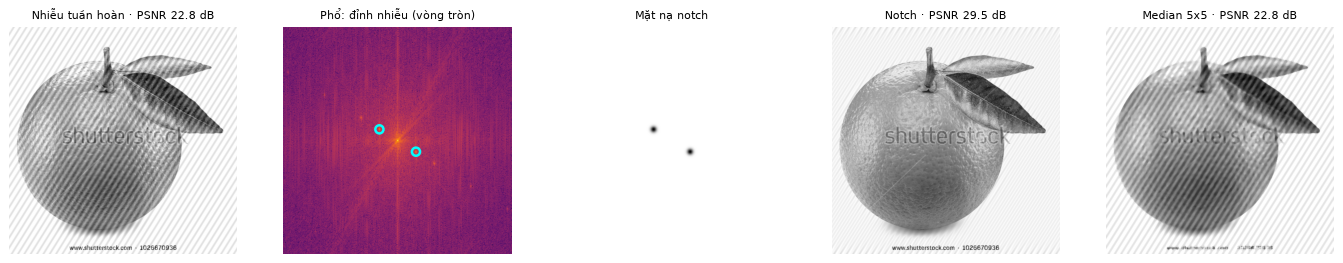

,MSE,PSNR_dB,SSIM
Ảnh nhiễu tuần hoàn,342.1,22.79,0.5031
Notch filter (tần số),72.51,29.53,0.8602
Gaussian LP D0=30 (tần số),232.5,24.47,0.6527
Median 5x5 (không gian),342.8,22.78,0.4427
Gaussian 7x7 (không gian),286.5,23.56,0.5245


In [11]:
pn = flt.add_periodic_noise(gray, amplitude=30, freq=(0.08, 0.05))
Fn = flt.fft_shifted(pn)
peaks = flt.find_spectral_peaks(Fn, n=1)
notch = flt.notch_mask(gray.shape, peaks, radius=4)
restored = np.clip(flt.apply_frequency_filter(pn, notch), 0, 255).astype(np.uint8)
alts = {'Ảnh nhiễu tuần hoàn': pn,
        'Notch filter (tần số)': restored,
        'Gaussian LP D0=30 (tần số)': np.clip(flt.apply_frequency_filter(pn, flt.lowpass_mask(gray.shape, 30)), 0, 255).astype(np.uint8),
        'Median 5x5 (không gian)': cv2.medianBlur(pn, 5),
        'Gaussian 7x7 (không gian)': cv2.GaussianBlur(pn, (7, 7), 0)}
per = pd.DataFrame({k: flt.quality(gray, v) for k, v in alts.items()}).T
per.to_csv(OUT / 'periodic_noise.csv')

fig, ax = plt.subplots(1, 5, figsize=(19, 4))
show(ax[0], pn, f'Nhiễu tuần hoàn · PSNR {per.loc["Ảnh nhiễu tuần hoàn", "PSNR_dB"]:.1f} dB')
show(ax[1], flt.log_magnitude(Fn), 'Phổ: đỉnh nhiễu (vòng tròn)', 'inferno')
for (r_, c_) in peaks:
    for rr, cc in [(r_, c_), (gray.shape[0] - r_, gray.shape[1] - c_)]:
        ax[1].add_patch(plt.Circle((cc, rr), 8, fill=False, ec='cyan', lw=2))
show(ax[2], notch, 'Mặt nạ notch')
show(ax[3], restored, f'Notch · PSNR {per.loc["Notch filter (tần số)", "PSNR_dB"]:.1f} dB')
show(ax[4], alts['Median 5x5 (không gian)'], f'Median 5x5 · PSNR {per.loc["Median 5x5 (không gian)", "PSNR_dB"]:.1f} dB')
save(fig, 'periodic_noise_notch.png')
per

## 5. Lưu và tóm tắt

In [12]:
summary = {
    'image': MAIN_IMG.name, 'size_wh': list(gray.shape[::-1]),
    'conv_scratch_max_abs_diff': float(verify.max_abs_diff.max()),
    'best_filter_gaussian_noise': best.iloc[[i for i, v in enumerate(best.noise) if v.startswith('Gaussian')][0]][['filter', 'k', 'PSNR_dB', 'SSIM']].to_dict(),
    'best_filter_salt_pepper': best.iloc[[i for i, v in enumerate(best.noise) if v.startswith('Muối')][0]][['filter', 'k', 'PSNR_dB', 'SSIM']].to_dict(),
    'canny_auto_thresholds': [lo, hi],
    'edge_F1_no_prefilter': float(edge_df.loc['không lọc trước', 'F1']),
    'edge_F1_best_prefilter': [edge_df.F1.idxmax(), float(edge_df.F1.max())],
    'conv_theorem_mean_abs_diff': float(d.mean()),
    'periodic_noise_psnr_noisy_vs_notch': [float(per.iloc[0].PSNR_dB), float(per.loc['Notch filter (tần số)', 'PSNR_dB'])],
}
(OUT / 'metrics.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
g_best, sp_best = summary['best_filter_gaussian_noise'], summary['best_filter_salt_pepper']
print(f'''TÓM TẮT TASK 1B (ảnh {MAIN_IMG.name})
- Tích chập tự cài khớp OpenCV: sai khác lớn nhất {summary["conv_scratch_max_abs_diff"]:.1e}.
- Nhiễu Gaussian: tốt nhất {g_best["filter"]} {g_best["k"]}x{g_best["k"]} (PSNR {g_best["PSNR_dB"]:.2f} dB, SSIM {g_best["SSIM"]:.3f}).
- Nhiễu muối tiêu: tốt nhất {sp_best["filter"]} {sp_best["k"]}x{sp_best["k"]} (PSNR {sp_best["PSNR_dB"]:.2f} dB, SSIM {sp_best["SSIM"]:.3f}).
- Canny trên ảnh nhiễu: F1 {summary["edge_F1_no_prefilter"]:.2f} khi không lọc -> {summary["edge_F1_best_prefilter"][1]:.2f} với {summary["edge_F1_best_prefilter"][0]}.
- Định lý tích chập: không gian vs tần số chênh trung bình {summary["conv_theorem_mean_abs_diff"]:.4f} mức xám.
- Nhiễu tuần hoàn: PSNR {summary["periodic_noise_psnr_noisy_vs_notch"][0]:.2f} dB -> {summary["periodic_noise_psnr_noisy_vs_notch"][1]:.2f} dB nhờ notch filter.''')

TÓM TẮT TASK 1B (ảnh kaggle_train_orange_16.jpg)
- Tích chập tự cài khớp OpenCV: sai khác lớn nhất 1.4e-13.
- Nhiễu Gaussian: tốt nhất bilateral 7x7 (PSNR 28.77 dB, SSIM 0.823).
- Nhiễu muối tiêu: tốt nhất median 3x3 (PSNR 30.52 dB, SSIM 0.911).
- Canny trên ảnh nhiễu: F1 0.26 khi không lọc -> 0.92 với Gaussian 5x5.
- Định lý tích chập: không gian vs tần số chênh trung bình 0.0165 mức xám.
- Nhiễu tuần hoàn: PSNR 22.79 dB -> 29.53 dB nhờ notch filter.


## 6. Nhận xét và hạn chế

- Chọn bộ lọc theo **loại nhiễu**, không có bộ lọc tốt nhất cho mọi trường hợp. Bảng PSNR/SSIM ở mục 2 là bằng chứng.
- MSE/PSNR chỉ có ý nghĩa khi có **ảnh sạch tham chiếu**. Ảnh upload thật trong app không có tham chiếu, nên app chỉ hiển thị kết quả lọc và tham số.
- Ideal low-pass gây **ringing**, do nó tương đương tích chập với hàm sinc. Gaussian tránh được hiện tượng này.
- Sau notch filter vẫn còn vân sọc mờ ở **vùng nền trắng**. Lý do: tại đó ảnh nhiễu đã bị cắt ở mức 255, là một phép phi tuyến, nên sinh thêm các hài bậc cao nằm ngoài đỉnh đã chặn.
- Tách vùng quả bằng ngưỡng Otsu trên kênh bão hoà phụ thuộc **nền ảnh**: ổn với nền trơn, sai khi nền cũng nhiều màu (bát, thớt gỗ, lá) hoặc nhiều quả chồng lên nhau.
- Ảnh dataset có nhiều độ phân giải khác nhau nên được thu nhỏ về cạnh dài 512 px để so sánh công bằng.